# The ladder and the margins on a second public dataset: sixteen months on a campus

Notebook 19 repeats the ladder on the public urban measurements of Medellín, four links over six months in one regime. This notebook does the same on the long-term LoRaWAN metadata of the University of Virginia campus (Nikseresht, Sobral, Goodall and Campbell, BuildSys 2025, https://doi.org/10.1145/3736425.3771960; data https://doi.org/10.18130/V3/RFTICK, CC BY 4.0): ten sensors and three gateways, 9 February 2024 to 11 June 2025, one uplink every five minutes, 2,091,512 receptions over 30 sensor-gateway pairs. Six sensors sit indoors, in offices, a laboratory and a classroom, four outdoors at building entrances and in a corridor; gateway A is on the roof of a five-story building, gateway B on the roof of a one-story building 0.8 to 1.2 km away, gateway C indoors on the second floor of a two-story building. The files `lorawan_combined_dataset.parquet` and `deployment_weather.parquet` of the Dataverse record go into `Data_Files/uva_lorawan/`.

What the data allow, and what they do not:

* Every sensor transmits at spreading factor 7 throughout (1,633 packets of sensor09 in May 2025 excepted), on the eight 125 kHz channels of US915 sub-band 2, so there is no spreading-factor regime to condition on. What the data have instead is drift: over the seventeen months, the monthly mean RSSI of the links to gateway A moves over a range of 15 to 22 dB, in step across the sensors, and that of the 18 m indoor link 03C over 19 dB (`CV_Results/uva_monthly_drift.csv`). The margins are therefore compared under drift, which is the case for the recency-weighted and the adaptive shifts of notebook 16.
* The transmit power is not recorded, so the path loss is known only up to a constant per link. Everything here works on the negative RSSI: the per-link mean, the anchor, the deviations and the margins do not need the constant, and the static model learns the level of each link from its distance and placement as it would from the path loss.
* A link is a sensor-gateway pair; the 22 pairs with at least 5,000 receptions are kept (the eight dropped have 24 to 4,248). Link 10C begins on 23 May 2025, inside the hold-out, so it is a link that no model has seen in training.
* The environmental inputs are the readings of the campus weather station (temperature, humidity, pressure, wind, rain) merged to each reception as the last reading within the hour; the station has gaps, the longest about two months, and 6 % of the receptions carry no SNR. Both stay missing and LightGBM handles them as missing values; the only requirement for a reception to count is a complete link history (rung H4).
* Same chronological split as notebook 00: the first 80 % of the receptions in time for training, five forward-chaining validation blocks inside it, the last 20 % (from 26 February 2025) as hold-out. Clock features in the local time zone (America/New_York). History features as in `history_features.build`; rungs as in notebook 13: H1 the link history, H4 adds the same-channel history, the clock and the spreading factor, H6 the SNR of earlier packets and the weather, H7 the link level, the distance and the indoor flags of sensor and gateway. The history rungs share one LightGBM setting, tuned on rung H4 as in notebook 13; the static input sets, with and without the weather and with the SNR of the predicted packet, are tuned on their own by the same search, so that no input set is scored with settings chosen for another.
* Rung H4 gets the margin six ways on rolling windows, as in notebook 16: a regression with one shift, with a shift per state (working hours x recent-spread tercile), a quantile model with one shift, with a recency-weighted shift (half-life 30 days), and with an adaptive shift. Then the unseen-sensor test of notebooks 13 and 19: fitted on the other sensors, tested on every link of the held-out sensor.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from skopt import BayesSearchCV
from skopt.space import Integer, Real
from history_features import build, H1, H4, H5
from margin_tools import pinball, shift_pooled, shift_groups, shift_weighted, aci, spread_groups, day_codes, boot_stat, transitions, clustering_ratio

RANDOM_STATE = 42
TAU = 0.99
HALF_LIFE = 30          # days, recency-weighted shift, as in notebook 16

In [2]:
# The public files, as released: one row per reception of a packet by a gateway. Coordinates and placement from the dataset's README.
SENSORS = {"sensor01": (38.0328110, -78.5095524, 1), "sensor02": (38.0321764, -78.5107493, 0), "sensor03": (38.0321568, -78.5108207, 1), "sensor04": (38.0327080, -78.5097230, 0),
           "sensor05": (38.0333228, -78.5111476, 0), "sensor06": (38.0332850, -78.5111832, 1), "sensor07": (38.0328110, -78.5095524, 1), "sensor08": (38.0347279, -78.5135257, 0),
           "sensor09": (38.0346453, -78.5134932, 1), "sensor10": (38.0318946, -78.5102145, 1)}                      # latitude, longitude, indoor
GATEWAYS = {"gatewayA": (38.0317195, -78.5108640, 0), "gatewayB": (38.0365606, -78.5225695, 0), "gatewayC": (38.0322023, -78.5106216, 1)}

def distance_m(p, q):
    la1, lo1, la2, lo2 = np.radians([p[0], p[1], q[0], q[1]])
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return float(2 * 6371000 * np.arcsin(np.sqrt(h)))

raw = pd.read_parquet("Data_Files/uva_lorawan/lorawan_combined_dataset.parquet")
df = pd.DataFrame({"sensor": raw["Sensor Alias"], "gateway": raw["Gateway Alias"], "t": raw["Timestamp"], "PL": -raw["RSSI (dBm)"], "snr": raw["SNR (dB)"],
                   "SF": raw["Spreading Factor (-)"].astype(int), "frequency": raw["Frequency (Hz)"] / 1e6})
df["device_id"] = df["sensor"].str[-2:] + df["gateway"].str[-1]                                           # the link, e.g. 01A
df = df[df.groupby("device_id")["PL"].transform("size") >= 5000]
geometry = pd.DataFrame([{"sensor": s, "gateway": g, "distance": distance_m(SENSORS[s], GATEWAYS[g]), "sensor_indoor": SENSORS[s][2], "gateway_indoor": GATEWAYS[g][2]}
                         for s in SENSORS for g in GATEWAYS])
df = df.merge(geometry, on=["sensor", "gateway"]).sort_values("t").reset_index(drop=True)

w = pd.read_parquet("Data_Files/uva_lorawan/deployment_weather.parquet")
weather = pd.DataFrame({"t": w["Timestamp"], "temperature": (w["Temperature ( F )"] - 32) / 1.8, "humidity": w["Humidity ( RH )"], "pressure": w["Barometric Pressure ( INHG )"] * 33.8639,
                        "wind": w["Wind Speed ( MPH )"] * 0.44704, "rain": w["Accumulated Rain ( IN )"] * 25.4}).sort_values("t")
WEATHER = ["temperature", "humidity", "pressure", "wind", "rain"]
df = pd.merge_asof(df, weather, on="t", direction="backward", tolerance=pd.Timedelta("1h"))          # the last station reading within the hour; missing in the station's gaps

# The chronological split and the forward-chaining folds of notebook 00 (fold -1 = first training block, 0-4 = validation blocks, 9 = hold-out)
split = int(len(df) * 0.8)
fold = np.full(len(df), 9)
fold[:split] = -1
for k, (_, va) in enumerate(TimeSeriesSplit(n_splits=5).split(df.iloc[:split])):
    fold[va] = k
df["fold"] = fold
links = df.groupby("device_id").agg(receptions=("PL", "size"), first=("t", "min"), last=("t", "max"), distance_m=("distance", "first"), sensor_indoor=("sensor_indoor", "first"),
                                    gateway_indoor=("gateway_indoor", "first"), PL_mean=("PL", "mean"), PL_sd=("PL", "std"))
links["first"], links["last"] = links["first"].dt.date, links["last"].dt.date
display(links.round(1))
print(f"{len(df):,} receptions on {df['device_id'].nunique()} links; training {split:,} up to {df['t'].iloc[split - 1]:%Y-%m-%d %H:%M}, hold-out {len(df) - split:,} from "
      f"{df['t'].iloc[split]:%Y-%m-%d %H:%M}; weather missing for {df['temperature'].isna().mean():.1%} of the receptions, SNR for {df['snr'].isna().mean():.1%}")

,receptions,first,last,distance_m,sensor_indoor,gateway_indoor,PL_mean,PL_sd
device_id,,,,,,,,
01A,117049,2024-02-09,2025-06-11,167.1,1,0,93.4,9.5
01B,9443,2024-02-09,2025-06-11,1213.9,1,0,109.6,9.2
01C,95134,2024-02-09,2025-06-11,115.5,1,1,108.6,2.9
02A,115072,2024-02-09,2025-06-11,51.8,0,0,99.9,9.5
02C,150752,2024-02-09,2025-06-11,11.5,0,1,79.1,6.5
03A,118105,2024-02-09,2025-05-19,48.8,1,0,90.7,9.2
03B,11690,2024-02-09,2025-05-23,1139.6,1,0,112.6,6.8
03C,123429,2024-02-09,2025-05-23,18.2,1,1,61.7,6.2
04A,117002,2024-02-09,2025-06-11,148.6,0,0,94.8,9.9


2,084,086 receptions on 22 links; training 1,667,268 up to 2025-02-26 20:10, hold-out 416,818 from 2025-02-26 20:10; weather missing for 11.8% of the receptions, SNR for 6.0%


In [3]:
# The drift: the monthly mean path loss (negative RSSI) of every link, months with at least 1,000 receptions; its range over the months, and per gateway
# how closely the monthly means of its links move together (mean pairwise correlation)
monthly = df.assign(month=df["t"].dt.strftime("%Y-%m")).groupby(["device_id", "month"])["PL"].agg(["mean", "size"])
monthly = monthly[monthly["size"] >= 1000]["mean"].unstack("month")
drift = pd.DataFrame({"gateway": [l[-1] for l in monthly.index], "months": monthly.notna().sum(axis=1), "monthly range dB": monthly.max(axis=1) - monthly.min(axis=1)}, index=monthly.index)
drift["mean correlation with the other links of its gateway"] = np.nan
for g in sorted(drift.gateway.unique()):
    links = drift.index[drift.gateway == g]
    r = monthly.loc[links].T.corr(min_periods=6)
    drift.loc[links, "mean correlation with the other links of its gateway"] = [r.loc[l].drop(l).mean() for l in links]
drift.to_csv("CV_Results/uva_monthly_drift.csv")
display(drift.round(2))

,gateway,months,monthly range dB,mean correlation with the other links of its gateway
device_id,,,,
01A,A,17,17.87,0.83
01B,B,2,15.13,NaN
01C,C,17,5.60,0.35
02A,A,17,18.07,0.81
02C,C,17,21.89,-0.20
03A,A,16,15.28,0.58
03B,B,5,9.27,NaN
03C,C,16,18.58,0.09
04A,A,17,19.19,0.84


In [4]:
# History features and rungs; the weather station takes the place of the room sensors
d = build(df, tz="America/New_York").sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
rungs = {"H1": H1, "H4": H4, "H6": H5 + WEATHER, "H7": H5 + WEATHER + ["a", "distance", "sensor_indoor", "gateway_indoor"]}
static = ["distance", "sensor_indoor", "gateway_indoor", "frequency"] + WEATHER
ok = (d["y"].notna() & d[rungs["H4"]].notna().all(axis=1)).to_numpy()      # a complete link history; missing weather and missing earlier SNR stay missing
y, a, PL = d["y"].to_numpy(), d["a"].to_numpy(), d["PL"].to_numpy()
link, sensor, gateway = d["device_id"].to_numpy(), d["sensor"].to_numpy(), d["gateway"].to_numpy()
work, s20 = d["work"].to_numpy().astype(int), d["s20"].to_numpy()
day = day_codes(d["t"])
val, ev = ok & (fold >= 0) & (fold < 9), ok & (fold == 9)
X_all = d[sorted(set(sum(rungs.values(), []) + static + ["snr"]))]
print(f"receptions with an anchor and a complete history: {ok.sum():,} of {len(d):,}; validation {val.sum():,}; hold-out {ev.sum():,}")

receptions with an anchor and a complete history: 2,061,943 of 2,084,086; validation 1,376,868; hold-out 413,048


In [5]:
# One light search per input set on every tenth training row, folds kept, as in notebook 13: rung H4 gives the settings of every history rung,
# and each static input set is searched on its own in the same space, so that it is not scored with settings chosen for the history inputs
sub = np.flatnonzero(ok & (fold < 9))[::10]
cv_sub = [(np.flatnonzero(fold[sub] < k), np.flatnonzero(fold[sub] == k)) for k in range(5)]
space = {"num_leaves": Integer(15, 255), "learning_rate": Real(0.01, 0.2, prior="log-uniform"), "n_estimators": Integer(200, 1500), "min_child_samples": Integer(5, 1000),
         "subsample": Real(0.6, 1.0), "colsample_bytree": Real(0.5, 1.0), "reg_lambda": Real(0.1, 30, prior="log-uniform")}

def search(cols, target):
    t0 = time.time()
    bs = BayesSearchCV(lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=4, verbose=-1), space, n_iter=20, cv=cv_sub, scoring="neg_root_mean_squared_error",
                       n_jobs=8, n_points=2, random_state=RANDOM_STATE, refit=False)
    bs.fit(X_all[cols].to_numpy()[sub], target[sub])
    best = dict(bs.best_params_)
    print(f"search RMSE {-bs.best_score_:.3f} dB after {time.time() - t0:.0f} s: {best}")
    return best

best = search(rungs["H4"], y)
json.dump(best, open("CV_Results/uva_best_params.json", "w"), indent=1, default=float)
params = dict(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best)
static_sets = {"static inputs without the weather": ["distance", "sensor_indoor", "gateway_indoor", "frequency"], "static inputs": static, "static inputs + SNR of the same packet": static + ["snr"]}
static_best = {}
for name, cols in static_sets.items():
    print(name, end=": ")
    static_best[name] = search(cols, PL)
json.dump(static_best, open("CV_Results/uva_static_best_params.json", "w"), indent=1, default=float)
static_params = {name: dict(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **p) for name, p in static_best.items()}

def oof_and_test(make, cols, target):
    X = X_all[cols].to_numpy()
    p = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = ok & (fold < k), ok & (fold == k)
        p[va] = make().fit(X[tr], target[tr]).predict(X[va])
    p[ev] = make().fit(X[ok & (fold < 9)], target[ok & (fold < 9)]).predict(X[ev])
    return p

search RMSE 2.674 dB after 83 s: {'colsample_bytree': 0.9440218534563989, 'learning_rate': 0.010458337914036341, 'min_child_samples': 5, 'n_estimators': 719, 'num_leaves': 255, 'reg_lambda': 0.31344885968421393, 'subsample': 0.8366059318878761}
static inputs without the weather: 

search RMSE 8.559 dB after 83 s: {'colsample_bytree': 0.5055131474105163, 'learning_rate': 0.021478494835860045, 'min_child_samples': 12, 'n_estimators': 545, 'num_leaves': 229, 'reg_lambda': 28.41342792178114, 'subsample': 0.9292685048823873}
static inputs: 

search RMSE 6.911 dB after 106 s: {'colsample_bytree': 0.7573761413840239, 'learning_rate': 0.01, 'min_child_samples': 259, 'n_estimators': 418, 'num_leaves': 255, 'reg_lambda': 15.85108393910671, 'subsample': 0.7217406519270689}
static inputs + SNR of the same packet: 

search RMSE 6.243 dB after 92 s: {'colsample_bytree': 0.5, 'learning_rate': 0.01, 'min_child_samples': 5, 'n_estimators': 529, 'num_leaves': 255, 'reg_lambda': 0.1, 'subsample': 0.6}


In [6]:
# The ladder: predicted level for every rung, and the references that need no model
pred = {}
t0 = time.time()
mean = np.full(len(d), np.nan)                                       # the mean of each link over the earlier training packets
for k in list(range(5)) + [9]:
    earlier = d[ok & (fold < k)] if k < 9 else d[ok & (fold < 9)]
    mean[fold == k] = d.loc[fold == k, "device_id"].map(earlier.groupby("device_id")["PL"].mean())
pred["per-link mean"] = mean
pred["previous hour mean"] = a
for name, cols in static_sets.items():
    pred[name] = oof_and_test(lambda: lgb.LGBMRegressor(**static_params[name]), cols, PL)
for name, cols in rungs.items():
    pred[f"rung {name}"] = a + oof_and_test(lambda: lgb.LGBMRegressor(**params), cols, y)
print(f"{time.time() - t0:.0f} s")

te = np.flatnonzero(ev & np.isfinite(mean))                          # link 10C has no training packets and so no per-link mean; it is tested below as a link never seen
dd = pd.factorize(day[te])[0]
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
rows = []
for name, p in pred.items():
    e = PL - p
    c = shift_pooled(e[val & np.isfinite(e)], TAU)
    r = boot_stat(dd, np.column_stack([e[te] ** 2, np.ones(len(te))]), lambda T: np.sqrt(T[:, 0] / T[:, 1]))
    rows.append({"inputs": name, "hold-out RMSE": r[0], "lo": r[1], "hi": r[2], "validation RMSE": rmse(e[val & np.isfinite(e)]), "99 % shift dB": c, "coverage": float((e[te] <= c).mean()),
                 "pinball x 1000": 1000 * pinball(e[te], c, TAU).mean()})
ladder = pd.DataFrame(rows).set_index("inputs")
ladder.to_csv("CV_Results/uva_ladder.csv")
display(ladder.round(3))
tail = pd.DataFrame([{"block": k, "without the weather": np.quantile((PL - pred["static inputs without the weather"])[ok & (fold == k)], 0.99),
                      "with the weather": np.quantile((PL - pred["static inputs"])[ok & (fold == k)], 0.99)} for k in range(5)]).set_index("block")
tail.to_csv("CV_Results/uva_static_tail_by_block.csv")
print("99 % quantile of the out-of-fold error by validation block, static inputs without and with the weather (dB)")
display(tail.round(1))

740 s


,hold-out RMSE,lo,hi,validation RMSE,99 % shift dB,coverage,pinball x 1000
inputs,,,,,,,
per-link mean,6.940,6.640,7.248,8.802,14.464,0.973,216.781
previous hour mean,3.328,3.252,3.407,3.309,10.000,0.991,121.903
static inputs without the weather,6.806,6.502,7.123,8.868,14.670,0.979,199.199
static inputs,5.830,5.455,6.244,7.255,22.542,0.997,239.102
static inputs + SNR of the same packet,5.295,4.968,5.695,6.551,19.577,0.999,203.222
rung H1,3.172,3.110,3.226,3.119,9.394,0.990,116.045
rung H4,2.774,2.715,2.828,2.629,7.722,0.988,104.721
rung H6,2.736,2.679,2.789,2.605,7.798,0.989,102.089
rung H7,2.727,2.670,2.781,2.611,7.865,0.990,101.936


99 % quantile of the out-of-fold error by validation block, static inputs without and with the weather (dB)


,without the weather,with the weather
block,,
0,14.5,27.2
1,15.7,20.6
2,14.5,12.8
3,14.5,12.2
4,13.4,12.3


In [7]:
# The SNR of the predicted packet, link by link: the SNR at which each link operates and the slope of its path loss on that SNR (training packets),
# against the hold-out RMSE of the static model without and with that SNR, with 95 % intervals from resampling days
without, with_ = "static inputs", "static inputs + SNR of the same packet"
snr = d["snr"].to_numpy()
rows = []
for l in ["all"] + sorted(np.unique(link[te])):
    i = te if l == "all" else te[link[te] == l]
    j = ok & (fold < 9) & np.isfinite(snr)
    if l != "all":
        j &= link == l
    e0, e1 = (PL - pred[without])[i], (PL - pred[with_])[i]
    r = boot_stat(pd.factorize(day[i])[0], np.column_stack([e1 ** 2, e0 ** 2, np.ones(len(i))]), lambda T: np.sqrt(T[:, 0] / T[:, 2]) - np.sqrt(T[:, 1] / T[:, 2]))
    rows.append({"link": l, "hold-out packets": len(i), "median SNR dB": np.median(snr[j]), "SNR 10 %": np.percentile(snr[j], 10), "SNR 90 %": np.percentile(snr[j], 90),
                 "path loss per dB of SNR": np.polyfit(snr[j], PL[j], 1)[0] if l != "all" else np.nan,
                 "RMSE without": rmse(e0), "RMSE with": rmse(e1), "difference": r[0], "lo": r[1], "hi": r[2]})
leak = pd.DataFrame(rows).set_index("link")
leak.to_csv("CV_Results/uva_snr_leak.csv")
display(leak.round(3))

,hold-out packets,median SNR dB,SNR 10 %,SNR 90 %,path loss per dB of SNR,RMSE without,RMSE with,difference,lo,hi
link,,,,,,,,,,
all,407863,9.0,-5.00,15.0,NaN,5.830,5.295,-0.534,-0.658,-0.423
01A,22845,10.0,2.00,15.0,-0.199,6.087,5.834,-0.253,-0.469,-0.049
01B,1746,-6.0,-8.00,-2.0,-0.941,3.891,3.834,-0.056,-0.129,0.015
01C,22693,-4.0,-8.00,3.0,-0.428,2.834,2.087,-0.747,-0.939,-0.568
02A,23329,4.0,-4.00,10.0,-0.242,5.629,5.429,-0.200,-0.293,-0.107
02C,34502,15.0,14.00,15.0,-2.358,9.414,7.670,-1.744,-2.362,-1.109
03A,18429,12.0,3.00,15.0,-0.167,5.773,5.469,-0.304,-0.517,-0.085
03B,64,-7.0,-9.00,-4.0,0.305,7.456,7.273,-0.182,-0.838,0.022
03C,23883,15.0,14.00,15.0,-1.090,7.901,7.837,-0.064,-0.180,0.053


In [8]:
# Rung H4 with the margin built six ways on rolling windows, as in notebook 16: a regression with one shift or a shift per state (working hours x recent-spread tercile),
# a quantile model with one shift, a recency-weighted shift or an adaptive shift
X4 = rungs["H4"]
reg = pred["rung H4"] - a
q = oof_and_test(lambda: lgb.LGBMRegressor(objective="quantile", alpha=TAU, **params), X4, y)
windows = [1, 2, 3, 4, 9]
margin, cuts, rows_of = {}, {}, {}
for w in windows:
    t_ = np.flatnonzero(ok & (fold == w))
    cal = np.flatnonzero(ok & (fold >= 0) & (fold < w))
    cut = np.quantile(s20[cal], [1 / 3, 2 / 3])
    rows_of[w], cuts[w] = t_, cut
    state = lambda i: work[i] * 3 + spread_groups(s20[i], cut)
    age = (d["t"].iloc[t_].min() - d["t"].iloc[cal]).dt.total_seconds().to_numpy() / 86400
    for kind, b in (("reg", reg), ("q", q)):
        score = y[cal] - b[cal]
        margin[(w, f"{kind} pooled")] = b[t_] + shift_pooled(score, TAU)
        if kind == "reg":
            margin[(w, "reg state table")] = b[t_] + shift_groups(score, state(cal), state(t_), TAU)
        else:
            margin[(w, "q recency")] = b[t_] + shift_weighted(score, age, TAU, HALF_LIFE)
            m = np.empty(len(t_))
            for l in np.unique(link[t_]):
                i = np.flatnonzero(link[t_] == l)
                m[i] = aci(b[t_][i], y[t_][i], score, TAU, (1 - TAU) / 20)
            margin[(w, "q ACI")] = m
methods = ["reg pooled", "reg state table", "q pooled", "q recency", "q ACI"]

rows = []
for w in windows:
    t_ = rows_of[w]
    for method in methods:
        m = margin[(w, method)]
        miss = y[t_] > m
        states = {"all": np.ones(len(t_), bool), "other hours": work[t_] == 0, "working hours": work[t_] == 1, "calm spread": spread_groups(s20[t_], cuts[w]) == 0,
                  "volatile spread": spread_groups(s20[t_], cuts[w]) == 2}
        states.update({f"gateway {g[-1]}": gateway[t_] == g for g in np.unique(gateway[t_])})
        states.update({str(k): link[t_] == k for k in np.unique(link[t_]) if (link[t_] == k).sum() >= 1000})
        for g, sel in states.items():
            rows.append(dict(window=w, method=method, state=g, n=int(sel.sum()), coverage=1 - miss[sel].mean(), margin=m[sel].mean(), pinball=1000 * pinball(y[t_][sel], m[sel], TAU).mean()))
margins = pd.DataFrame(rows)
margins.to_csv("CV_Results/uva_margins.csv", index=False)
print("coverage at the 99 % target by window and method, all packets")
display(margins[margins.state == "all"].pivot(index="method", columns="window", values="coverage").loc[methods].round(4))
print("hold-out coverage by state")
display(margins[margins.window == 9].pivot(index="state", columns="method", values="coverage")[methods].round(4))
print("hold-out mean margin above the anchor (dB) and pinball loss x 1000, all packets")
display(margins[(margins.window == 9) & (margins.state == "all")].set_index("method")[["margin", "pinball"]].loc[methods].round(3))

coverage at the 99 % target by window and method, all packets


window,1,2,3,4,9
method,,,,,
reg pooled,0.9879,0.9934,0.9919,0.9885,0.9879
reg state table,0.9892,0.9920,0.9913,0.9909,0.9896
q pooled,0.9915,0.9942,0.9928,0.9924,0.9910
q recency,0.9918,0.9937,0.9906,0.9905,0.9888
q ACI,0.9907,0.9908,0.9905,0.9905,0.9903


hold-out coverage by state


method,reg pooled,reg state table,q pooled,q recency,q ACI
state,,,,,
01A,0.9783,0.9864,0.9897,0.9881,0.9896
01B,0.9983,0.9914,0.9948,0.9931,0.9943
01C,1.0000,0.9945,0.9943,0.9921,0.9906
02A,0.9866,0.9912,0.9934,0.9923,0.9907
02C,0.9979,0.9952,0.9931,0.9895,0.9899
03A,0.9765,0.9836,0.9868,0.9852,0.9901
03C,0.9996,0.9981,0.9972,0.9956,0.9902
04A,0.9578,0.9802,0.9839,0.9816,0.9897
04C,0.9997,0.9934,0.9917,0.9888,0.9908


hold-out mean margin above the anchor (dB) and pinball loss x 1000, all packets


,margin,pinball
method,,
reg pooled,7.736,104.380
reg state table,6.294,80.306
q pooled,6.041,74.459
q recency,5.828,74.461
q ACI,6.089,72.913


In [9]:
# Independence of the misses on the hold-out (successive receptions of a link at most ten minutes apart, two uplink intervals), and the differences between the margins
t_ = rows_of[9]
dd = pd.factorize(day[t_])[0]
rows = []
for method in methods:
    T = transitions(d["t"].iloc[t_], link[t_], y[t_] > margin[(9, method)], max_gap=600)
    r = boot_stat(dd, T, clustering_ratio)
    rows.append(dict(method=method, miss_clustering=r[0], lo=r[1], hi=r[2]))
independence = pd.DataFrame(rows).set_index("method")
independence.to_csv("CV_Results/uva_independence.csv")
display(independence.round(2))
rows = []
for m1, m2 in [("q pooled", "reg pooled"), ("q pooled", "reg state table"), ("q recency", "q pooled"), ("q ACI", "q pooled")]:
    diff = pinball(y[t_], margin[(9, m1)], TAU) - pinball(y[t_], margin[(9, m2)], TAU)
    r = boot_stat(dd, np.column_stack([diff, np.ones(len(t_))]), lambda T: 1000 * T[:, 0] / T[:, 1])
    rows.append(dict(a=m1, b=m2, pinball_difference=r[0], lo=r[1], hi=r[2]))
contrasts = pd.DataFrame(rows)
contrasts.to_csv("CV_Results/uva_margin_contrasts.csv", index=False)
display(contrasts.round(3))

,miss_clustering,lo,hi
method,,,
reg pooled,5.18,4.35,6.29
reg state table,3.72,2.98,4.59
q pooled,2.89,2.01,4.03
q recency,2.53,1.89,3.30
q ACI,2.47,1.74,3.41


,a,b,pinball_difference,lo,hi
0,q pooled,reg pooled,-29.921,-31.029,-28.795
1,q pooled,reg state table,-5.847,-6.316,-5.364
2,q recency,q pooled,0.002,-0.113,0.123
3,q ACI,q pooled,-1.546,-1.848,-1.238


In [10]:
# A sensor the model has never seen, as in notebooks 13 and 19: fit on the links of the other sensors with validation folds 0 to 3, calibrate the 99 % margin on their
# fold 4, test on every link of the held-out sensor in the hold-out, with the margin kept as calibrated or adapted to the link's own misses as it goes;
# the reference with the sensor in training is the same model fitted on folds 0 to 3 of all sensors, so that the two differ only by the sensor
rows = []
for name, cols, target in (("static inputs", static, PL), ("rung H1", rungs["H1"], y), ("rung H4", rungs["H4"], y)):
    X = X_all[cols].to_numpy()
    make = lambda: lgb.LGBMRegressor(**static_params.get(name, params))
    fit_all = ok & (fold >= 0) & (fold < 4)
    m_all = make().fit(X[fit_all], target[fit_all])
    for s in sorted(np.unique(sensor)):
        other = sensor != s
        fit_m, cal_m = ok & other & (fold >= 0) & (fold < 4), ok & other & (fold == 4)
        m = make().fit(X[fit_m], target[fit_m])
        e_cal = target[cal_m] - m.predict(X[cal_m])
        c = shift_pooled(e_cal, TAU)
        for l in np.unique(link[ev & (sensor == s)]):
            test_m = ev & (link == l)
            b = m.predict(X[test_m])
            e_test = target[test_m] - b
            adaptive = aci(b, target[test_m], e_cal, TAU, (1 - TAU) / 20)
            rows.append({"inputs": name, "link": l, "hold-out packets": int(test_m.sum()), "RMSE unseen": rmse(e_test), "bias unseen": float(e_test.mean()),
                         "RMSE with the sensor in training": rmse(target[test_m] - m_all.predict(X[test_m])) if l != "10C" else np.nan, "99 % shift from the other sensors": c,
                         "coverage": float((e_test <= c).mean()), "adaptive margin": float((adaptive - b).mean()), "adaptive coverage": float((target[test_m] <= adaptive).mean())})
unseen = pd.DataFrame(rows).set_index(["inputs", "link"])
unseen.to_csv("CV_Results/uva_unseen_sensor.csv")
pd.set_option("display.max_rows", 100)
display(unseen.round(3))

hold-out packets  RMSE unseen  bias unseen  \
inputs        link                                               
static inputs 01A              22845        7.909        4.586   
              01B               1746        3.949        1.530   
              01C              22693        4.085        2.801   
              02A              23329        6.905        4.623   
              02C              34502       14.176       12.313   
              03A              18429        8.601       -6.562   
              03B                 64        7.384       -0.587   
              03C              23883       25.700      -25.368   
              04A              22431       11.034       -8.800   
              04C              26894        3.069       -0.279   
              05A              24996        7.709       -5.445   
              05C              27101        3.560       -1.499   
              06A              25372        6.683       -3.139   
              06C               9974        3.152        1.658   
              07A              22525        6.414       -0.559   
              07B               1747        3.747        0.337   
              07C              27361        3.756       -2.031   
              08A              22544        5.999       -1.045   
              08B              15287        3.993       -0.955   
              09A              23543        6.199        0.245   
              09B              10597        5.326        3.328   
              10C               5185        3.955        1.881   
rung H1       01A              22845        4.109        0.036   
              01B               1746        2.174        0.025   
              01C              22693        1.764       -0.001   
              02A              23329        4.041        0.011   
              02C              34502        1.434        0.034   
              03A              18429        3.914       -0.026   
              03B                 64        2.064       -0.277   
              03C              23883        0.917        0.021   
              04A              22431        4.975        0.029   
              04C              26894        2.265        0.005   
              05A              24996        3.485        0.012   
              05C              27101        1.517        0.018   
              06A              25372        2.031       -0.002   
              06C               9974        1.141        0.011   
              07A              22525        4.940        0.097   
              07B               1747        2.203        0.057   
              07C              27361        1.755        0.000   
              08A              22544        4.493       -0.007   
              08B              15287        2.510       -0.023   
              09A              23543        4.469        0.005   
              09B              10597        2.376       -0.021   
              10C               5185        2.225        0.032   
rung H4       01A              22845        3.681       -0.052   
              01B               1746        2.144       -0.037   
              01C              22693        1.596       -0.013   
              02A              23329        3.390       -0.034   
              02C              34502        1.151        0.046   
              03A              18429        3.545       -0.055   
              03B                 64        2.150       -0.293   
              03C              23883        0.691        0.021   
              04A              22431        4.331       -0.042   
              04C              26894        1.947        0.019   
              05A              24996        2.554        0.003   
              05C              27101        1.376        0.014   
              06A              25372        1.732       -0.028   
              06C               9974        1.092       -0.014   
              07A              22525        3.944        0.0

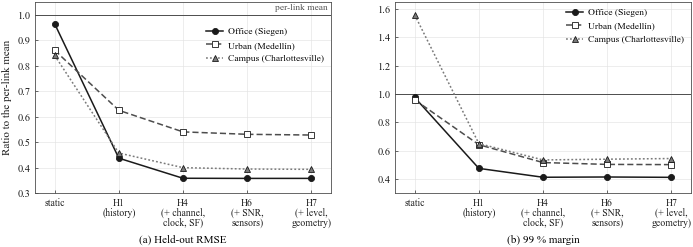

In [11]:
# Figure: the ladder on the three datasets relative to the per-link mean of each (its RMSE and its 99 % margin), in ink and greys;
# from the result files of notebooks 13, 15, 19 and this notebook
import paper_figures as pf
pf.use()
siegen = pd.read_csv("CV_Results/information_by_family.csv", index_col=[0, 1]).loc["LGBM"]
mean_siegen = pd.read_csv("CV_Results/history_benchmark.csv", index_col=[0, 1]).loc[("link mean", "-")]
medellin = pd.read_csv("CV_Results/medellin_ladder.csv", index_col=0)
campus = pd.read_csv("CV_Results/uva_ladder.csv", index_col=0)
names = ["static inputs", "rung H1", "rung H4", "rung H6", "rung H7"]
curves = [("Office (Siegen)", [siegen.loc[r, "hold-out RMSE"] / mean_siegen["hold-out RMSE"] for r in ("static", "H1", "H4", "H6", "H7")],
           [siegen.loc[r, "margin 0.99"] / mean_siegen["margin 0.99"] for r in ("static", "H1", "H4", "H6", "H7")], pf.INK, "o", "-", pf.INK),
          ("Urban (Medellín)", [medellin.loc[n, "hold-out RMSE"] / medellin.loc["per-link mean", "hold-out RMSE"] for n in names],
           [medellin.loc[n, "99 % shift dB"] / medellin.loc["per-link mean", "99 % shift dB"] for n in names], pf.INK2, "s", (0, (4, 2)), "white"),
          ("Campus (Charlottesville)", [campus.loc[n, "hold-out RMSE"] / campus.loc["per-link mean", "hold-out RMSE"] for n in names],
           [campus.loc[n, "99 % shift dB"] / campus.loc["per-link mean", "99 % shift dB"] for n in names], "#7a7a7a", "^", (0, (1.2, 1.4)), "#7a7a7a")]
TICKS = ["static", "H1\n(history)", "H4\n(+ channel,\nclock, SF)", "H6\n(+ SNR,\nsensors)", "H7\n(+ level,\ngeometry)"]
fig = plt.figure(figsize=(pf.PAGE, 2.6))
gs = fig.add_gridspec(1, 2, wspace=0.22, left=0.075, right=0.99, top=0.985, bottom=0.25)
ax = [fig.add_subplot(gs[0, i]) for i in range(2)]
for name, rmse_ratio, margin_ratio, colour, marker, ls, fill in curves:
    assert 0.3 < min(rmse_ratio + margin_ratio) and max(rmse_ratio) < 1.05 and max(margin_ratio) < 1.65      # nothing clipped
    for a_, ratio in zip(ax, (rmse_ratio, margin_ratio)):
        a_.plot(range(5), ratio, color=colour, lw=1.1, ls=ls, marker=marker, ms=4.4, mfc=fill, mec=pf.INK, mew=0.6, label=name, zorder=3)
for a_ in ax:
    a_.axhline(1, color=pf.INK2, lw=0.7, zorder=1)
    a_.set_xticks(range(5))
    a_.set_xticklabels(TICKS, fontsize=7, linespacing=0.95)
    a_.set_xlim(-0.3, 4.3)
ax[0].set_ylim(0.3, 1.05)
ax[1].set_ylim(0.3, 1.65)
ax[0].text(4.25, 1.01, "per-link mean", ha="right", va="bottom", fontsize=6.8, color=pf.INK2)
ax[0].set_ylabel("Ratio to the per-link mean")
ax[0].legend(loc="upper right", fontsize=6.8, bbox_to_anchor=(1.0, 0.9))
ax[1].legend(loc="upper right", fontsize=6.8)
pf.subcaptions(fig, ax, ["(a) Held-out RMSE", "(b) 99 % margin"])
fig.savefig("Figures/ladder_three_datasets.png")
plt.show()

**Reading of the results.**

* **The ladder replicates a third time, under drift.** The hold-out RMSE falls from 6.94 dB for the per-link mean to 3.33 for the previous-hour mean, 3.17 with the link's history, 2.77 with the same-channel history, the clock and the spreading factor, and 2.73 and 2.72 with the earlier SNR, the weather, the link level and the geometry. The 99 % margin falls from 14.5 dB for the per-link mean to 9.4, 7.7, 7.8 and 7.8 dB: 53 to 54 % of the per-link mean's margin from rung H4 on, against 41 % in the office (LightGBM; 41 to 52 % across the six families) and 52 % in Medellín. The RMSE at rung H4 is 40 % of the per-link mean's, 36 % in the office, 54 % in Medellín.
* **A fixed level does not hold under drift.** The per-link mean's margin, calibrated on the validation year, covers 97.3 % of the hold-out; the previous-hour mean and every history rung cover 98.8 to 99.1 %.
* **The weather carries the season, but only once the training data span it.** The static model with the weather reaches 5.83 dB on the hold-out, against 6.81 dB without it and 6.94 for the per-link mean: the level of the links to the rooftop gateways moves with the season and the station records that. Its 99 % margin, 22.5 dB, comes from the first two validation blocks, where weather terms fitted on two to five months were applied to the months that followed (99 % quantiles of 27.2 and 20.6 dB, against 12.2 to 12.8 dB from the third block on); without the weather the static model has the per-link mean's tail, 14.7 dB. The office showed nothing of the kind over one year on one floor.
* **The SNR of the same packet**, with the static model tuned anew for that input set, lowers the static RMSE from 5.83 to 5.30 dB (-0.53 dB, interval -0.66 to -0.42) and does not reach the link's history (3.17 dB). Between the links it ranges from -1.74 dB (02C) to +0.20 dB (06A); on the five links of the indoor gateway that operate within 4 dB of 0 dB median SNR (01C, 04C, 05C, 06C, 07C) it is -0.42 to -1.18 dB. Leakage, as in Medellín.
* **Margins under drift.** The regression with one shift covers 98.8 % of the hold-out but 97.6 % on the links to gateway A, 96.9 % in the volatile third of the packets and 95.8 % on the worst link (04A), while the links to the indoor gateway are covered 99.8 to 100 %; in the validation windows its worst link is at 95.2 %. A shift per state (working hours x recent spread) lowers the pinball loss by 23 % (104 to 80 per thousand), the quantile model with one shift by a further 7 % (74.5; -5.8 [-6.3, -5.4] per thousand against the state table), and the adaptive shift by 2 % more (72.9; -1.5 [-1.8, -1.2]) while bringing every link to 99.0 to 99.4 % and the worst link of a validation window to 98.9 %. The recency-weighted shift changes nothing (+0.00 [-0.11, +0.12]): the quantile model's inputs already follow the drift, the calibration scores do not need to. After a miss, the next packet misses 5.2 times [4.4, 6.3] as often as after a covered packet with the one-shift regression and 2.5 times [1.7, 3.4] with the quantile model and the adaptive shift. Mean margins above the anchor 7.7, 6.3, 6.0, 5.8 and 6.1 dB.
* **A sensor the model has never seen.** With the static inputs the error on the held-out sensor's links is 3.1 to 25.7 dB (02C 14.2 and 03C 25.7 dB: the two closest links to the indoor gateway, 12 and 18 m, with nothing like them among the other sensors). With the link's history the fit on blocks 0 to 3 of the other nine sensors lands within 0.02 dB (rung H1) and within 0.05 dB (rung H4) of the same fit with the sensor included, on all 21 links; link 10C, which no model saw in training, gets 2.23 dB at rung H1 and 1.80 dB at rung H4. The fixed 99 % margin from the other sensors covers 96.0 to 100 % at rung H4 (the links to gateway A 96.0 to 100 %, the others 99.8 to 100 %), the adaptive shift 98.9 to 100 % (10C 99.7 %). Link 03B has 64 hold-out packets.
* **Limits.** Negative RSSI in place of path loss, since the transmit power is not recorded (the per-link constant drops out of everything but the static level); one spreading factor throughout; one weather station for all links; sixteen months with one hold-out of three and a half months; 22 links from 10 sensors, so the unseen-sensor test leaves out two or three links at a time.